 Implementing Feedforward neural networks with Keras and TensorFlow
a. Import the necessary packages
b. Load the training and testing data (MNIST/CIFAR10)
c. Define the network architecture using Keras
d. Train the model using SGD
e. Evaluate the network
f. Plot the training loss and accuracy

In [5]:
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt 
import random

In [16]:
mnist = tf.keras.datasets.mnist
(x_train,y_train), (x_test, y_test ) = mnist.load_data()
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print(x_train.shape, y_train.shape)


(60000, 28, 28) (60000,)


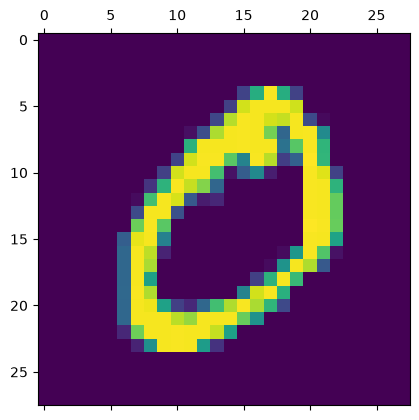

In [8]:
plt.matshow(x_train[1])

In [ ]:
model = keras.Sequential([
  keras.layers.Flatten(input_shape = (28,28)),
  keras.layers.Dense(128, activation='relu'),
  keras.layers.Dense(10,activation='softmax')
])

model.summary()

c:\Users\Sanika Mogal\OneDrive\Desktop\Dl practicals\ml_env\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
model.compile(
  optimizer='sgd',
  loss='sparse_categorical_crossentropy',
  metrics=['accuracy']

)

In [13]:

print(x_train.shape)
print(y_train.shape)
print(x_test.shape)
print(y_test.shape)

(60000, 28, 28)
(60000,)
(10000, 28, 28)
(10000,)


In [14]:
print("Trainable variables:", len(model.trainable_variables))
print("Training samples:", len(x_train))
print("Label samples:", len(y_train))

model.train_on_batch(x_train[:32], y_train[:32])

Trainable variables: 4
Training samples: 60000
Label samples: 60000


[2.399418354034424, 0.0625]

In [15]:
print(model.summary())
print("Optimizer:", model.optimizer)
print("Loss:", model.loss)
print("Metrics:", model.metrics)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,772 (397.55 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

None
Optimizer: <keras.src.optimizers.sgd.SGD object at 0x000002BFE457CAD0>
Loss: sparse_categorical_crossentropy
Metrics: [<Mean name=loss>, <CompileMetrics name=compile_metrics>]


In [16]:
result = model.train_on_batch(x_train[:32], y_train[:32])
print("Training result:", result)

Training result: [2.3600616455078125, 0.0625]


In [17]:
history = model.fit(
    x_train, y_train,
    validation_data=(x_test, y_test),
    epochs=10,
    batch_size=32
)


Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8378 - loss: 0.6342 - val_accuracy: 0.9033 - val_loss: 0.3572
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9043 - loss: 0.3406 - val_accuracy: 0.9175 - val_loss: 0.2959
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9171 - loss: 0.2924 - val_accuracy: 0.9253 - val_loss: 0.2657
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9264 - loss: 0.2620 - val_accuracy: 0.9331 - val_loss: 0.2433
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9334 - loss: 0.2386 - val_accuracy: 0.9368 - val_loss: 0.2229
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9388 - loss: 0.2195 - val_accuracy: 0.9403 - val_loss: 0.2085
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9431 - loss: 0.2040 - val_accuracy: 0.9448 - val_loss: 0.1953
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9466 - loss: 0.1901 - 

In [18]:
loss, accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9531 - loss: 0.1656
Test Loss: 0.16561195254325867
Test Accuracy: 0.9531000256538391


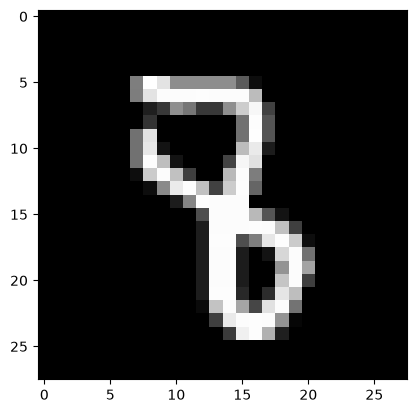

In [19]:
n = random.randint(0, 9999)

plt.imshow(x_test[n], cmap='gray')
plt.show()

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 814us/step


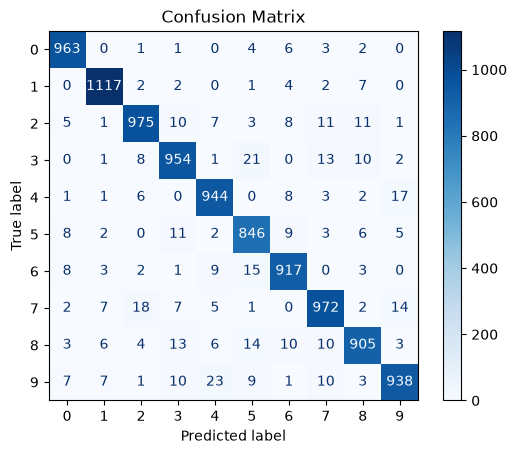

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Predict test data
y_pred = model.predict(x_test)

# Convert predictions into class labels
y_pred = np.argmax(y_pred, axis=1)

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap='Blues')

plt.title("Confusion Matrix")
plt.show()